## Lab 5
### Tandem Project Proposal
#### 11/3 Will Stelter, Owen Johnson

#### We intend to reproduce the identification of the proposed stellar stream named "Nyx."

#### Stellar streams are satellite galaxies of the Milky Way which have been stretched into line-like arrangements said to resemble rivers of light (hence "stellar stream").
#### The original forms of these satellites lend themselves to producing current-day populations of stars which, per population, usually have similar metallicities and distances from Earth. That is to say, the stars in each stream often look similar to each other.

#### In order to identify the stream's stars, we have a few different options for data selection and analysis. We could use photometric data in order to identify candidates by their ages and distances, which will provide the primary means of identification. As a follow up to the photometric work, we could also use spectroscopic data to identify those stars' metallicities and radial velocities. Alternatively, we could refer to information published in GAIA data releases and proceed directly to analysis. 


#### Stars in a stellar stream should all: be about the same age, have the same metallicity, be about the same distance from the center of the Milky Way (this is wrong, what's the right way to say this), have a similar motion (radial velocity//proper motion?), and perhaps other characteristics
#### We'll analyze the data with the following steps:
#### 1. Take photometric data depicting the night sky in on-sky coordinates.
#### 2. Section off a range of that data including where Nyx is thought to be
#### 3. Tag the stars in the region
#### 4. Determine which stars satisfy the above requirements 
#### 5. Determine how to assign significance to those characteristics

#### step 4 expanded (star analysis tools)
#### Color indexing -> stellar temperature
#### Star age -> isochrone map. Will be useful for demonstrating that a selected population (those in the proposed stream) are of the same age
#### velocity - surveys may already have this listed!

#### As far as data sets go, we have a few options, including: the overall astronomical surveys DESI and GAIA. We may also take data from other papers whose work we wish to reproduce or emulate.
#### Sources will be listed!

### initial list of sources

#### https://zenodo.org/records/3579379
#### https://arxiv.org/abs/1907.07190 - Lina Necib Nyx radial velocity detection paper
#### https://github.com/linoush/nyx_stream/blob/main/nyx_ids.csv - Lina Necib's 94 Nyx stars


### documentation
#### https://docs.astropy.org/projects/astroquery/en/latest/gaia/gaia.html


In [12]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

import astropy
import astropy.units as u
from astropy.coordinates import SkyCoord

In [3]:

from astroquery.gaia import Gaia
Gaia.MAIN_GAIA_TABLE = "gaiadr2.gaia_source"  # Select Data Release 2

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [9]:
# specify the location of the CSV file
filename = '/home/jovyan/Stelter434/nyx_ids.csv'

# read the CSV file into a pandas DataFrame
data = pd.read_csv(filename)

# Check the dimensions of the DataFrame
print("Data dimensions:", data.shape)

# Display the column names
print("Column names:", data.columns)

# Display information about the data types
data.info()

# Display the first five rows
data.head()

Data dimensions: (94, 5)
Column names: Index(['Unnamed: 0', 'ra', 'dec', 'phot_g_mean_mag', 'source_id'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       94 non-null     int64  
 1   ra               94 non-null     float64
 2   dec              94 non-null     float64
 3   phot_g_mean_mag  94 non-null     float64
 4   source_id        94 non-null     int64  
dtypes: float64(3), int64(2)
memory usage: 3.8 KB


,Unnamed: 0,ra,dec,phot_g_mean_mag,source_id
0,0,190.677308,8.012331,12.205640,3710694930194636672
1,1,250.246941,24.332745,12.678221,1299837840290894208
2,2,129.657756,-46.556767,11.895650,5521612777549913088
3,3,200.888099,-62.520908,13.155975,5868299273531920512
4,4,292.563948,-78.170068,10.356856,6365839623773507840


In [10]:
# Set 
# Extract right ascension
ra = data['ra'].to_numpy()

# Extract declination
dec = data['dec'].to_numpy()

# Extract Gaia G-band magnitude
g_mag = data['phot_g_mean_mag'].to_numpy()

# Extract Gaia source identifiers
source_id = data['source_id'].to_numpy()

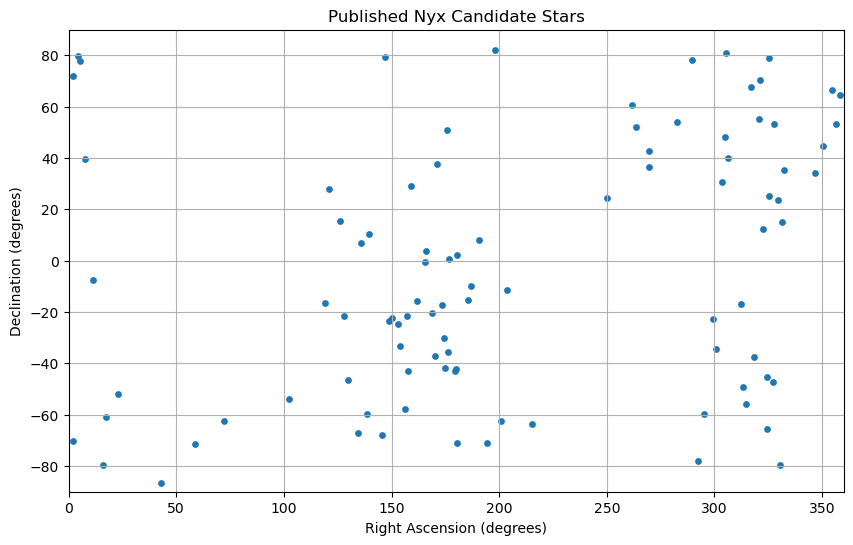

In [11]:
# plot the positions of the Nyx candidates
plt.figure(figsize=(10, 6))

plt.scatter(ra, dec, s=15)

plt.xlabel('Right Ascension (degrees)')
plt.ylabel('Declination (degrees)')
plt.title('Published Nyx Candidate Stars')

plt.xlim(0, 360)
plt.ylim(-90, 90)

plt.grid()
plt.show()

In [14]:
# construct an equatorial coordinate object
coords = SkyCoord(ra=ra * u.deg, dec=dec * u.deg, frame='icrs')
# transform equatoial coordinates into Galactic coordinates
galactic_coords = coords.galactic

# extract Galactic longitude and latitude
l = galactic_coords.l.deg
b = galactic_coords.b.deg

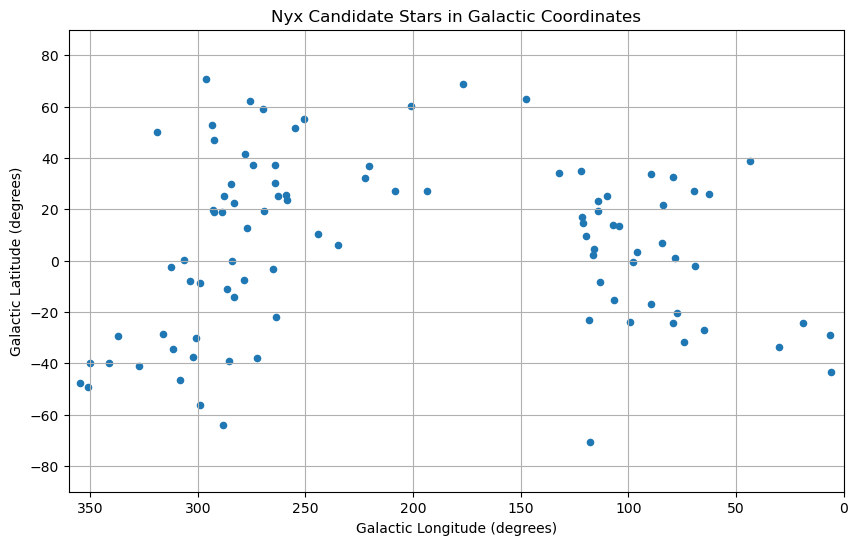

In [17]:
# plot Nyx candidates in Galactic coordinates
plt.figure(figsize=(10, 6))

plt.scatter(l, b, s=20)

plt.xlabel('Galactic Longitude (degrees)')
plt.ylabel('Galactic Latitude (degrees)')
plt.title('Nyx Candidate Stars in Galactic Coordinates')

plt.xlim(360, 0)
plt.ylim(-90, 90)

plt.grid()
plt.show()




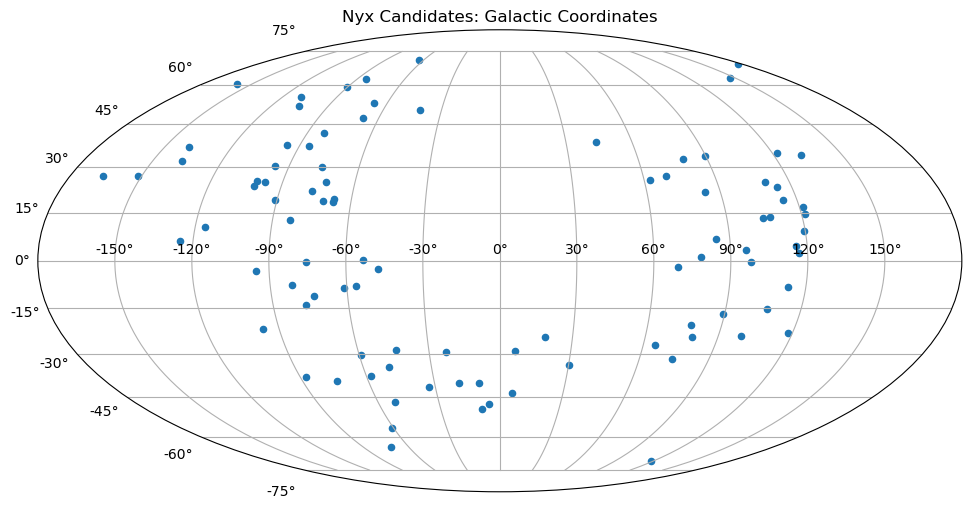

In [19]:
# convert Galactic longitude and latitude to radians
l_rad = galactic_coords.l.wrap_at(180 * u.deg).radian
b_rad = galactic_coords.b.radian

# create Mollweide projection
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection='mollweide')

# plot the stars
ax.scatter(l_rad, b_rad, s=20)

# display grid and title
ax.grid(True)
ax.set_title('Nyx Candidates: Galactic Coordinates')

plt.show()